# From pixel to class, advanced: time series, spatial validation and area estimates

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/image_classification_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [From pixel to class](https://openskylab.space/edu_viz_image_classification.html) · [česká verze](image_classification_pro_cs.ipynb)

The advanced version of the classification notebook. Instead of one image you work with three Sentinel-2 images from spring, summer and autumn 2024 near Roztoky, write the minimum distance classifier yourself, check accuracy with spatial validation and estimate class areas with their uncertainty, as is done in practice. Part of the code you write yourself.

**Goal:** build features from a time series, write and check your own classifier, compare random and spatial validation, measure what each image adds, and estimate class areas with a confidence interval following good practice (Olofsson et al. 2014).

**Data:** three Sentinel-2 L2A images of tile 33UVR (27 April, 21 July and 21 September 2024) from the Earth Search catalogue on AWS, a 4 × 4 km window around Roztoky and Suchdol; reference ESA WorldCover 10 m 2021 v200. About 60 MB is downloaded.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 75 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and three images

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestCentroid
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Read a cloud raster and resample it to grid = (transform, crs, height, width)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Reflectance of all Sentinel-2 L2A bands in a square around a point (10 m grid in the tile's UTM)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # since processing baseline 04.00 (2022) DN carry a +1000 offset; Earth Search has already removed it for newer items
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

S2A_33UVR_20240427_0_L2A: 2024-04-27, cloud-free 99.7% of the window


S2B_33UVR_20240721_0_L2A: 2024-07-21, cloud-free 99.7% of the window


S2A_33UVR_20240921_0_L2A: 2024-09-21, cloud-free 100.0% of the window


pixels cloud-free in all images and in the five classes: 158629 (99.1%)


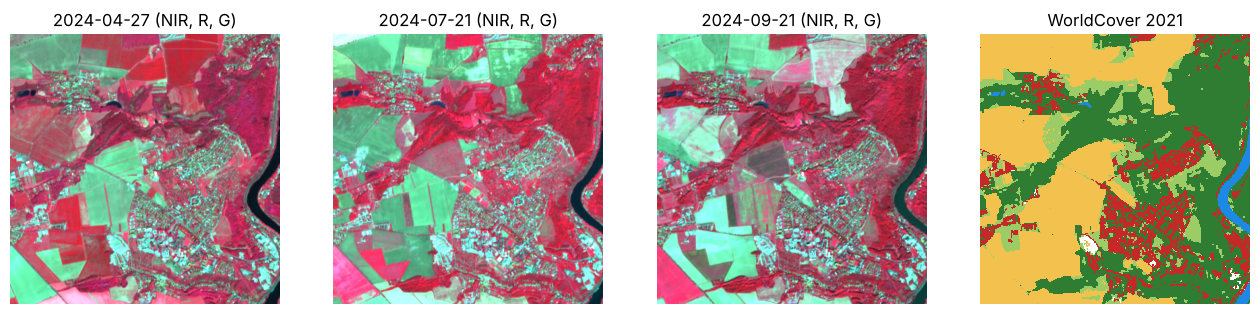

In [3]:
DATES = ["S2A_33UVR_20240427_0_L2A", "S2B_33UVR_20240721_0_L2A", "S2A_33UVR_20240921_0_L2A"]   # ◀ parameter: images of one year (spring, summer, autumn)
LON, LAT, HALF = 14.37, 50.14, 2000                                                          # ◀ parameter: window centre and half width (m)
stack, clear = {}, None
for item_id in DATES:
    refl, scl, wl, grid, item = s2_window(item_id, LON, LAT, HALF)
    day = item["properties"]["datetime"][:10]
    stack[day] = refl
    m = np.isin(scl, [4, 5, 6])
    clear = m if clear is None else clear & m
    print(f"{item_id}: {day}, cloud-free {m.mean():.1%} of the window")
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "forest", 30: "grassland", 40: "cropland", 50: "built-up", 80: "water"}
COLORS = ["#2e7d32", "#9ccc65", "#f2c14e", "#c62828", "#1e88e5"]
names = list(CLASSES.values())
y_img = np.full(wc.shape, -1)
for i, k in enumerate(CLASSES):
    y_img[wc == k] = i
ok = clear & (y_img >= 0)
print(f"pixels cloud-free in all images and in the five classes: {ok.sum()} ({ok.mean():.1%})")
fig, ax = plt.subplots(1, len(stack) + 1, figsize=(4 * (len(stack) + 1), 4))
for a, (day, r) in zip(ax, stack.items()):
    a.imshow(np.clip(np.dstack([r["nir"], r["red"], r["green"]]) / np.array([0.45, 0.15, 0.15]), 0, 1)); a.set_title(f"{day} (NIR, R, G)")
ax[-1].imshow(np.ma.masked_less(y_img, 0), cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[-1].set_title("WorldCover 2021")
for a in ax: a.axis("off")
plt.show()

## 2. Features from a time series

From every image we take the reflectance of ten bands and three indices: NDVI (greenness), NDWI (water, McFeeters 1996) and NDMI (leaf moisture). With three images every pixel has 39 features. The indices are functions in the `INDICES` dictionary, and you can add your own.

39 features: blue 04-27, green 04-27, red 04-27, rededge1 04-27, rededge2 04-27, rededge3 04-27, nir 04-27, nir08 04-27 …


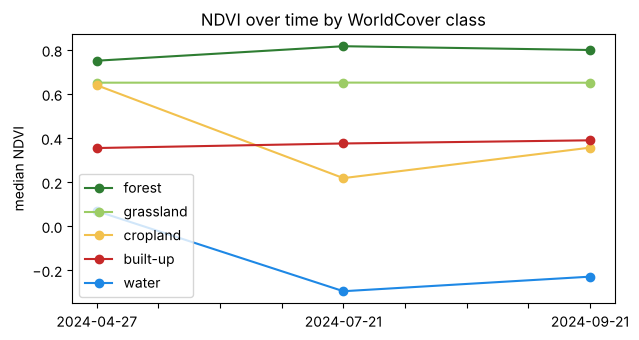

,2024-04-27,2024-07-21,2024-09-21
forest,0.75,0.82,0.80
grassland,0.65,0.65,0.65
cropland,0.64,0.22,0.36
built-up,0.35,0.38,0.39
water,0.07,-0.30,-0.23


In [4]:
INDICES = {                                                  # ◀ parameter: indices computed from every image; add your own
    "NDVI": lambda r: (r["nir"] - r["red"]) / (r["nir"] + r["red"]),
    "NDWI": lambda r: (r["green"] - r["nir"]) / (r["green"] + r["nir"]),
    "NDMI": lambda r: (r["nir08"] - r["swir16"]) / (r["nir08"] + r["swir16"]),
}
FEAT_BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def features(days):
    """Features for the chosen days: band reflectance and indices. Returns an array (rows, columns, features) and their names."""
    F, N = [], []
    for day in days:
        r = stack[day]
        for b in FEAT_BANDS:
            F.append(r[b]); N.append(f"{b} {day[5:]}")
        for name, f in INDICES.items():
            F.append(f(r)); N.append(f"{name} {day[5:]}")
    return np.dstack(F).astype(np.float32), N

DAYS = list(stack)
X_img, feat_names = features(DAYS)
print(f"{len(feat_names)} features:", ", ".join(feat_names[:8]), "…")
prof = pd.DataFrame({day: [np.median(INDICES["NDVI"](stack[day])[ok & (y_img == i)]) for i in range(5)] for day in DAYS}, index=names)
ax = prof.T.plot(marker="o", color=COLORS, figsize=(7, 3.5)); ax.set(ylabel="median NDVI", title="NDVI over time by WorldCover class"); plt.show()
prof.round(2)

> **✏️ Task 1.** How does the median NDVI of grassland and cropland change between April, July and September, and why (sowing, harvest, mowing)? Why are several images better than one for telling cropland from grassland? Add your own index to `INDICES`, for example NDRE = (nir − rededge1) / (nir + rededge1), run the cells again and watch in step 5 whether it helped.

*Your answer:* 

## 3. Your own minimum distance classifier

The minimum distance classifier assigns a pixel to the class whose centre (mean feature vector) is nearest. We write it in a few lines of numpy and check that it gives the same as `NearestCentroid` from scikit-learn. We train on the northern half of the window and test on the southern half. You write the branch for the Mahalanobis distance, which takes the spread and correlation of features within a class into account, yourself.

In [5]:
rng = np.random.default_rng(0)
n_class = 600                     # ◀ parameter: sample of pixels per class
idx = np.flatnonzero(ok.ravel())
samp = np.concatenate([rng.choice(idx[y_img.ravel()[idx] == k], n_class, replace=False) for k in range(5)])
X_all = X_img.reshape(-1, X_img.shape[2])
X, y = X_all[samp], y_img.ravel()[samp]
rows_, cols_ = np.unravel_index(samp, y_img.shape)
train = rows_ < y_img.shape[0] // 2                       # the north trains, the south tests
mu_, sd_ = X[train].mean(0), X[train].std(0)
Xs = (X - mu_) / sd_                                      # standardisation: every feature has mean 0 and variance 1

def min_distance(X_train, y_train, X_test, metric="euclid"):
    """Minimum distance to class centre classification."""
    centres = np.array([X_train[y_train == k].mean(0) for k in range(5)])
    if metric == "euclid":
        d = ((X_test[:, None, :] - centres[None, :, :]) ** 2).sum(2)
    elif metric == "mahalanobis":
        raise NotImplementedError("to do: covariance matrix of each class, its inverse and the distance (x − μ)ᵀ Σ⁻¹ (x − μ)")
    return d.argmin(1)

metric = "euclid"                 # ◀ parameter: "euclid", or "mahalanobis" once you have written it
pred = min_distance(Xs[train], y[train], Xs[~train], metric)
sk = NearestCentroid().fit(Xs[train], y[train]).predict(Xs[~train])
print(f"own classifier ({metric}): accuracy in the south {np.mean(pred == y[~train]):.1%}; agreement with scikit-learn NearestCentroid {np.mean(pred == sk):.1%}")
qda = QuadraticDiscriminantAnalysis(reg_param=1e-3).fit(Xs[train], y[train])
print(f"maximum likelihood (QDA) for comparison: {qda.score(Xs[~train], y[~train]):.1%}")

own classifier (euclid): accuracy in the south 77.1%; agreement with scikit-learn NearestCentroid 100.0%
maximum likelihood (QDA) for comparison: 82.0%


> **✏️ Task 2.** Write the `mahalanobis` branch in `min_distance` (covariance matrix of each class from the training pixels, `np.linalg.inv`, distance (x − μ)ᵀ Σ⁻¹ (x − μ)) and set `metric = "mahalanobis"`. How does the result compare with the Euclidean distance and with QDA? QDA is maximum likelihood: why does it still differ from your Mahalanobis distance (the ln |Σ| term and the prior probabilities)? Why is standardisation needed for the Euclidean distance? Try switching it off (`Xs = X`).

*Your answer:* 

## 4. Random or spatial validation?

Neighbouring pixels are similar. If we split the sample into training and test pixels at random, a test pixel often has a neighbour in training and the accuracy comes out too good. Spatial validation splits the sample by squares: a whole square is either in training or in testing (Roberts et al. 2017). We compare a random split, squares, and a north–south split.

In [6]:
BLOCK_M = 500                     # ◀ parameter: size of the squares for spatial validation (m)
rf = RandomForestClassifier(200, max_depth=12, random_state=0, n_jobs=-1)
blocks = (rows_ * 10 // BLOCK_M) * 10000 + cols_ * 10 // BLOCK_M
cv = {
    "random split (KFold)": cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=0)),
    f"squares {BLOCK_M} m (GroupKFold)": cross_val_score(rf, X, y, cv=GroupKFold(5), groups=blocks),
    "north × south": np.array([rf.fit(X[train], y[train]).score(X[~train], y[~train]), rf.fit(X[~train], y[~train]).score(X[train], y[train])]),
}
print(f"squares with at least one sample pixel: {len(np.unique(blocks))}")
pd.DataFrame({k: {"mean": v.mean(), "min": v.min(), "max": v.max()} for k, v in cv.items()}).T.round(3)

squares with at least one sample pixel: 64


,mean,min,max
random split (KFold),0.900,0.893,0.910
squares 500 m (GroupKFold),0.892,0.854,0.926
north × south,0.852,0.835,0.869


> **✏️ Task 3.** Why does the random split come out best and the north × south split worst? Set `BLOCK_M` to 200 and 1000 m: how do the mean and spread of accuracy change and why? Which number would you trust if the map were to be used in a neighbouring area, and which would you report?

*Your answer:* 

## 5. What each image adds

The course over time separates classes that look alike at one moment. We compute the accuracy of a random forest (spatial validation by squares) for each image alone, for pairs and for all three, and the F1 score of each class for the summer image and for all three.

In [7]:
day_of = np.array([n.split()[-1] for n in feat_names])
rows = {}
for r_ in range(1, len(DAYS) + 1):
    for combo in combinations(DAYS, r_):
        cols = np.isin(day_of, [d[5:] for d in combo])
        acc = cross_val_score(rf, X[:, cols], y, cv=GroupKFold(5), groups=blocks)
        rows[" + ".join(d[5:] for d in combo)] = {"features": int(cols.sum()), "accuracy (squares)": acc.mean()}
res = pd.DataFrame(rows).T
print(res.round(3).to_string())
one, allc = np.isin(day_of, DAYS[1][5:]), np.ones(len(day_of), bool)
f1 = {}
for label, cols in [(f"only {DAYS[1][5:]}", one), ("all images", allc)]:
    pr = cross_val_predict(rf, X[:, cols], y, cv=GroupKFold(5), groups=blocks)
    f1[label] = f1_score(y, pr, average=None)
pd.DataFrame(f1, index=names).round(2)

                       features  accuracy (squares)
04-27                      13.0               0.831
07-21                      13.0               0.845
09-21                      13.0               0.849
04-27 + 07-21              26.0               0.879
04-27 + 09-21              26.0               0.883
07-21 + 09-21              26.0               0.876
04-27 + 07-21 + 09-21      39.0               0.892


,only 07-21,all images
forest,0.80,0.84
grassland,0.75,0.81
cropland,0.86,0.94
built-up,0.83,0.87
water,0.98,0.99


> **✏️ Task 4.** Which single image is best, and which pair? How much did all three images help, and for which class most? Explain it with the NDVI plot from step 2. When would another image no longer help, and what would help more then (other features, a better reference, more training pixels)?

*Your answer:* 

## 6. A map and area estimates with uncertainty

A class area counted from the map (number of pixels times pixel area) carries the classification errors. Good practice (Olofsson et al. 2014) is to estimate the area from a random sample of check pixels drawn separately in each map class (stratified sampling) and to report a confidence interval. We make the map from half of the squares and estimate areas on the rest of the area. The reference here is WorldCover, which we have for every pixel, so we can compare the estimate with the true total.

area 792 ha, overall accuracy 86.3%, check pixels 500


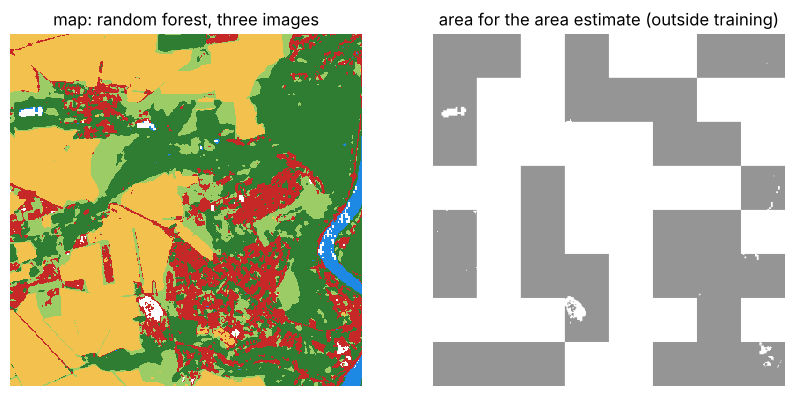

,from the map (ha),estimate from the sample (ha),± 95 % (ha),"WorldCover, all pixels (ha)",user's accuracy,producer's accuracy
forest,290.34,331.77,19.38,325.79,0.94,0.82
grassland,110.17,84.80,16.41,87.96,0.60,0.78
cropland,256.38,280.69,10.78,278.11,1.00,0.91
built-up,118.02,79.55,13.17,85.90,0.62,0.92
water,17.29,15.39,1.07,14.44,0.89,1.00


In [8]:
n_h = 100                         # ◀ parameter: sample of check pixels in each map class
blk = (np.indices(y_img.shape)[0] * 10 // BLOCK_M) * 10000 + np.indices(y_img.shape)[1] * 10 // BLOCK_M
ub = np.unique(blk)
train_blocks = rng.choice(ub, len(ub) // 2, replace=False)
in_train = np.isin(blk, train_blocks).ravel() & ok.ravel()
pool = np.flatnonzero(in_train)
tr = np.concatenate([rng.choice(pool[y_img.ravel()[pool] == k], min(400, int((y_img.ravel()[pool] == k).sum())), replace=False) for k in range(5)])
rf.fit(X_all[tr], y_img.ravel()[tr])
mapped = np.full(y_img.size, -1)
mapped[ok.ravel()] = rf.predict(X_all[ok.ravel()])
area = ok.ravel() & ~in_train                              # area outside the training squares
W = np.array([np.mean(mapped[area] == h) for h in range(5)])
cm = np.zeros((5, 5))
for h in range(5):
    s = rng.choice(np.flatnonzero(area & (mapped == h)), n_h, replace=False)
    cm[h] = np.bincount(y_img.ravel()[s], minlength=5)
n_i = cm.sum(1, keepdims=True)
p = W[:, None] * cm / n_i                                  # estimated area proportions (row = map, column = reference)
se = np.sqrt((W[:, None] ** 2 * (cm / n_i) * (1 - cm / n_i) / (n_i - 1)).sum(0))
A = area.sum() * 100 / 1e4                                 # ha
out = pd.DataFrame({"from the map (ha)": W * A, "estimate from the sample (ha)": p.sum(0) * A, "± 95 % (ha)": 1.96 * se * A,
                    "WorldCover, all pixels (ha)": [np.mean(y_img.ravel()[area] == k) * A for k in range(5)],
                    "user's accuracy": np.diag(cm) / n_i[:, 0], "producer's accuracy": np.diag(p) / p.sum(0)}, index=names)
print(f"area {A:.0f} ha, overall accuracy {np.trace(p):.1%}, check pixels {int(cm.sum())}")
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.ma.masked_less(mapped.reshape(y_img.shape), 0), cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[0].set_title("map: random forest, three images")
ax[1].imshow(np.where(area.reshape(y_img.shape), 1.0, np.nan), cmap="Greys", vmin=0, vmax=2); ax[1].set_title("area for the area estimate (outside training)")
for a in ax: a.axis("off")
plt.show()
out.round(2)

> **✏️ Task 5.** Which classes does the map overestimate and which does it underestimate? Is the WorldCover total closer to the map area or to the sample estimate, and does it fall inside the ±95 % interval? Set `n_h` to 30 and 300: how does the interval change and why? In practice you do not have a reference for every pixel: why is the map area not enough then? And why is not even WorldCover the “truth” (its overall accuracy is about 77 %, Zanaga et al. 2022)?

*Your answer:* 

> **✏️ Extension (optional).** Try another place: find three cloud-free images of one year (spring, summer, autumn) in the Earth Search catalogue, change `DATES`, `LON` and `LAT`, and the WorldCover tile in the `WORLDCOVER` variable according to the location (3 × 3° tiles, e.g. N48E015 for Moravia). Do the conclusions of steps 4 to 6 hold?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); AWS Open Data registry (`sentinel-cogs`), Earth Search catalogue (Element 84). Free use with attribution.
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment* 148, 42–57. https://doi.org/10.1016/j.rse.2014.02.015
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* 40, 913–929. https://doi.org/10.1111/ecog.02881
- Congalton, R. G., Green, K. (2019). *Assessing the Accuracy of Remotely Sensed Data: Principles and Practices*, 3rd ed. CRC Press.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### How to cite

OpenSkyLab (2026). From pixel to class, advanced: time series, spatial validation and area estimates [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/image_classification_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*